# 04 — Evidence audit, claim ledger, figures, and package

Run this notebook only after 00–03 complete. It does not force weak
results into positive claims. Instead, it builds a claim ledger with
`SUPPORTED`, `NOT_SUPPORTED`, or `LIMITED` status, creates compact
paper-ready figures, records checksums and the environment, and
produces one evidence ZIP.


In [1]:
import subprocess
import sys

# Install only dependencies that are absent or version-sensitive in Colab.
# The final environment manifest records every resolved version.
packages = [
    "duckdb==1.3.2",
    "osqp==1.0.4",
    "sqlglot==27.0.0",
    "pyarrow==19.0.1",
]
subprocess.check_call(
    [sys.executable, "-m", "pip", "install", "--quiet", *packages]
)
print("Required packages are available.")


Required packages are available.


In [2]:
from pathlib import Path
import hashlib
import importlib
import json
import os
import sys

try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

USE_GOOGLE_DRIVE = True
if IN_COLAB and USE_GOOGLE_DRIVE:
    drive.mount("/content/drive")
    default_root = "/content/drive/MyDrive/Arbiter_ICDE_2027"
else:
    default_root = "/content/Arbiter_ICDE_2027"

PROJECT_ROOT = Path(os.environ.get("ARBITER_PROJECT_ROOT", default_root))
active_path = PROJECT_ROOT / "active_run.json"
if not active_path.exists():
    raise FileNotFoundError(
        "Run Notebook 00 first. It creates active_run.json and the shared code."
    )
active = json.loads(active_path.read_text(encoding="utf-8"))
RUN_MODE = active["run_mode"]
if active.get("suite_version") != "2026-08-01-audited-v4":
    raise RuntimeError(
        "The active run was created by an older suite. Run the audited "
        "Notebook 00 before continuing."
    )
RUN_DIR = PROJECT_ROOT / active["run_directory"]
CODE_DIR = PROJECT_ROOT / "code"
if not CODE_DIR.exists():
    raise FileNotFoundError("Shared code is missing. Rerun Notebook 00.")
manifest_path = CODE_DIR / "code_manifest.json"
if not manifest_path.exists():
    raise FileNotFoundError("Shared-code manifest is missing. Rerun Notebook 00.")
expected_hashes = json.loads(manifest_path.read_text(encoding="utf-8"))
for name, expected_hash in expected_hashes.items():
    module_path = CODE_DIR / name
    if not module_path.is_file():
        raise FileNotFoundError(f"Shared module is missing: {name}")
    observed_hash = hashlib.sha256(module_path.read_bytes()).hexdigest()
    if observed_hash != expected_hash:
        raise RuntimeError(f"Shared module hash mismatch: {name}")
code_dir_text = str(CODE_DIR.resolve())
if code_dir_text not in sys.path:
    sys.path.insert(0, code_dir_text)
for module_name in [
    "arbiter_core",
    "arbiter_workload",
    "arbiter_experiments",
    "arbiter_data",
]:
    sys.modules.pop(module_name, None)
importlib.invalidate_caches()
config = json.loads((RUN_DIR / "run_config.json").read_text(encoding="utf-8"))
print(f"Active run: {RUN_MODE}")
print(f"Run directory: {RUN_DIR}")


Mounted at /content/drive
Active run: full
Run directory: /content/drive/MyDrive/Arbiter_ICDE_2027/runs/full_audited_v4


In [3]:
from pathlib import Path
import json
import os
import shutil
import zipfile

# Use a run-local writable cache. This prevents harmless but
# confusing Matplotlib configuration warnings in restricted
# runtimes and keeps the user's global configuration untouched.
matplotlib_cache = RUN_DIR / ".matplotlib-cache"
matplotlib_cache.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("MPLCONFIGDIR", str(matplotlib_cache))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from arbiter_core import checksum_manifest, environment_manifest
from arbiter_data import save_json

workload_dir = RUN_DIR / "00_workload"
proposal_dir = RUN_DIR / "01_proposals_attacks"
protocol_dir = RUN_DIR / "02_release_protocol"
scale_dir = RUN_DIR / "03_scalability"
output_dir = RUN_DIR / "04_evidence"
figures_dir = output_dir / "figures"
tables_dir = output_dir / "paper_tables"
for directory in [output_dir, figures_dir, tables_dir]:
    if directory == output_dir and directory.exists():
        shutil.rmtree(directory)
    directory.mkdir(parents=True, exist_ok=True)

compiler = pd.read_csv(workload_dir / "compiler_metrics.csv")
compiler_timing = pd.read_csv(
    workload_dir / "compiler_timing.csv"
)
sql_assets = pd.read_csv(workload_dir / "sql_assets.csv")
compiled_relations = pd.read_csv(
    workload_dir / "compiled_relations.csv"
)
ground_truth_relations = pd.read_csv(
    workload_dir / "ground_truth_relations.csv"
)
query_parse_audit = pd.read_csv(
    workload_dir / "query_parse_audit.csv"
)
semantic = pd.read_csv(
    workload_dir / "semantic_execution_checks.csv"
)
model = pd.read_csv(proposal_dir / "model_metrics_pooled.csv")
oof_predictions = pd.read_csv(
    proposal_dir / "oof_predictions.csv"
)
attacks = pd.read_csv(
    proposal_dir / "certified_row_attacks.csv"
)
attack_summary = pd.read_csv(
    proposal_dir / "certified_row_attack_summary.csv"
)
attack_family_summary = pd.read_csv(
    proposal_dir
    / "certified_row_attack_family_summary.csv"
)
gap_summary = pd.read_csv(
    proposal_dir / "omitted_relation_gap_summary.csv"
)
gap_cases = pd.read_csv(
    proposal_dir / "omitted_relation_gap_cases.csv"
)
faults = pd.read_csv(protocol_dir / "fault_injection.csv")
concurrency = pd.read_csv(
    protocol_dir / "stale_epoch_concurrency.csv"
)
end_to_end = pd.read_csv(
    protocol_dir / "end_to_end_release.csv"
)
scale_trials = pd.read_csv(scale_dir / "scale_trials_raw.csv")
build_trials = pd.read_csv(
    scale_dir / "constraint_build_trials.csv"
)
scale_summary = pd.read_csv(scale_dir / "scale_summary.csv")
paired = pd.read_csv(
    scale_dir / "paired_method_comparisons.csv"
)
ablation = pd.read_csv(scale_dir / "ablation_summary.csv")
incremental = pd.read_csv(
    scale_dir / "incremental_update_trials.csv"
)


In [4]:
# Recompute manuscript-facing summaries from raw rows. Saved
# summaries are accepted only if they match this independent pass.
from sklearn.metrics import mean_absolute_error, r2_score

def frames_match(left, right, sort_columns):
    try:
        left_sorted = left.sort_values(sort_columns).reset_index(drop=True)
        right_sorted = right.sort_values(sort_columns).reset_index(drop=True)
        right_sorted = right_sorted[left_sorted.columns]
        pd.testing.assert_frame_equal(
            left_sorted,
            right_sorted,
            check_dtype=False,
            check_exact=False,
            rtol=1e-10,
            atol=1e-12,
        )
        return True, "match"
    except Exception as exc:
        return False, f"{type(exc).__name__}: {exc}"

recomputed_attack_summary = (
    attacks.groupby(["dataset", "budget_fraction"], as_index=False)
    .agg(
        attacks=("attack_id", "size"),
        distinct_target_rows=("target_row_id", "nunique"),
        attack_success_rate=(
            "violations_before",
            lambda values: float((values > 0).mean()),
        ),
        released_rate=("released", "mean"),
        fallback_rate=("fallback_used", "mean"),
        unsafe_release_rate=("unsafe_release", "mean"),
        gate_p50_ms=("repair_ms", "median"),
        gate_p95_ms=(
            "repair_ms",
            lambda values: float(np.quantile(values, 0.95)),
        ),
        l1_median=("l1_adjustment", "median"),
        max_post_residual=("max_residual_after", "max"),
    )
)
recomputed_attack_summary["target_reuse_rate"] = 1.0 - (
    recomputed_attack_summary["distinct_target_rows"]
    / recomputed_attack_summary["attacks"]
)
recomputed_attack_family = (
    attacks.groupby(
        [
            "dataset",
            "budget_fraction",
            "target_constraint_type",
        ],
        as_index=False,
    )
    .agg(
        attacks=("attack_id", "size"),
        distinct_target_rows=("target_row_id", "nunique"),
        attack_success_rate=(
            "violations_before",
            lambda values: float((values > 0).mean()),
        ),
        released_rate=("released", "mean"),
        fallback_rate=("fallback_used", "mean"),
        unsafe_release_rate=("unsafe_release", "mean"),
        gate_p50_ms=("repair_ms", "median"),
        gate_p95_ms=(
            "repair_ms",
            lambda values: float(np.quantile(values, 0.95)),
        ),
        l1_median=("l1_adjustment", "median"),
    )
)
recomputed_attack_family["target_reuse_rate"] = 1.0 - (
    recomputed_attack_family["distinct_target_rows"]
    / recomputed_attack_family["attacks"]
)
recomputed_gap_summary = (
    gap_cases.groupby(
        ["dataset", "budget_fraction", "relation_type"],
        as_index=False,
    )
    .agg(
        cases=("relation_id", "size"),
        distinct_relations=("relation_id", "nunique"),
        candidate_target_violation_rate=(
            "certified_target_residual",
            lambda values: float(
                (values > config["tolerance"]).mean()
            ),
        ),
        incomplete_release_rate=(
            "released_by_incomplete_gate", "mean"
        ),
        gap_survival_rate=("gap_survives", "mean"),
        fallback_rate=("fallback_used", "mean"),
        gate_p50_ms=("gate_ms", "median"),
    )
)
recomputed_scale_summary = (
    scale_trials.groupby(
        ["dataset", "scale", "method"], as_index=False
    )
    .agg(
        trials=("method_runtime_ms", "size"),
        attack_cases=("attack_case_id", "nunique"),
        timing_repetitions=("repetition", "nunique"),
        runtime_p50_ms=("method_runtime_ms", "median"),
        runtime_p95_ms=(
            "method_runtime_ms",
            lambda values: float(np.quantile(values, 0.95)),
        ),
        runtime_p99_ms=(
            "method_runtime_ms",
            lambda values: float(np.quantile(values, 0.99)),
        ),
        snapshot_build_plus_gate_p50_ms=(
            "snapshot_build_plus_gate_ms", "median"
        ),
        snapshot_build_plus_gate_p95_ms=(
            "snapshot_build_plus_gate_ms",
            lambda values: float(np.quantile(values, 0.95)),
        ),
        verified_rate=("verified", "mean"),
        fallback_rate=("fallback_used", "mean"),
        rejection_rate=("rejected", "mean"),
        unsafe_release_rate=("unsafe_release", "mean"),
        mean_violations_before=("violations_before", "mean"),
        mean_violations_after=("violations_after", "mean"),
        max_residual_after=("max_residual_after", "max"),
        mean_l1_adjustment=("l1_adjustment", "mean"),
    )
    .sort_values(["dataset", "scale", "method"])
    .reset_index(drop=True)
)
model_rows = []
for (dataset, model_name, seed), group in oof_predictions.groupby(
    ["dataset", "model", "seed"], sort=False
):
    target = group["target_price"].to_numpy(float)
    prediction = group["oof_prediction"].to_numpy(float)
    model_rows.append(
        {
            "dataset": dataset,
            "model": model_name,
            "seed": int(seed),
            "pooled_r2": float(r2_score(target, prediction)),
            "pooled_mae": float(
                mean_absolute_error(target, prediction)
            ),
            "negative_predictions": int((prediction < 0).sum()),
        }
    )
recomputed_model = pd.DataFrame(model_rows)

def relation_key(record):
    relation_type = str(record["relation_type"])
    if relation_type == "decomposition":
        return (
            relation_type,
            str(record["target_id"]),
            tuple(
                sorted(json.loads(str(record["component_ids"])))
            ),
        )
    return (
        relation_type,
        str(record["derived_id"]),
        str(record["source_id"]),
    )

compiler_rows = []
for dataset, dataset_assets in sql_assets.groupby(
    "dataset", sort=False
):
    truth = {
        relation_key(record)
        for record in ground_truth_relations.loc[
            ground_truth_relations["dataset"] == dataset
        ].to_dict(orient="records")
    }
    found = {
        relation_key(record)
        for record in compiled_relations.loc[
            compiled_relations["dataset"] == dataset
        ].to_dict(orient="records")
    }
    true_positives = len(truth & found)
    false_positives = len(found - truth)
    false_negatives = len(truth - found)
    parse = query_parse_audit.loc[
        query_parse_audit["dataset"] == dataset
    ].merge(
        dataset_assets[["asset_id", "expected_supported"]],
        on="asset_id",
        how="left",
        validate="one_to_one",
    )
    expected_supported = (
        parse["expected_supported"].astype(str).str.lower() == "true"
    )
    parsed_supported = (
        parse["parsed_supported"].astype(str).str.lower() == "true"
    )
    compiler_rows.append(
        {
            "dataset": dataset,
            "assets": len(dataset_assets),
            "expected_supported_assets": int(
                expected_supported.sum()
            ),
            "parsed_supported_assets": int(
                parsed_supported.sum()
            ),
            "query_classification_accuracy": float(
                (expected_supported == parsed_supported).mean()
            ),
            "ground_truth_relations": len(truth),
            "compiled_relations": len(found),
            "true_positives": true_positives,
            "false_positives": false_positives,
            "false_negatives": false_negatives,
            "precision": (
                true_positives
                / (true_positives + false_positives)
                if true_positives + false_positives
                else 1.0
            ),
            "recall": (
                true_positives
                / (true_positives + false_negatives)
                if true_positives + false_negatives
                else 1.0
            ),
        }
    )
recomputed_compiler = pd.DataFrame(compiler_rows)

integrity_rows = []
for label, saved, recomputed, keys in [
    (
        "compiler metrics reconcile to relation/query raw rows",
        compiler,
        recomputed_compiler,
        ["dataset"],
    ),
    (
        "attack summary reconciles to raw rows",
        attack_summary,
        recomputed_attack_summary,
        ["dataset", "budget_fraction"],
    ),
    (
        "attack-family summary reconciles to raw rows",
        attack_family_summary,
        recomputed_attack_family,
        [
            "dataset",
            "budget_fraction",
            "target_constraint_type",
        ],
    ),
    (
        "omitted-row summary reconciles to raw rows",
        gap_summary,
        recomputed_gap_summary,
        ["dataset", "budget_fraction", "relation_type"],
    ),
    (
        "scale summary reconciles to raw rows",
        scale_summary,
        recomputed_scale_summary,
        ["dataset", "scale", "method"],
    ),
    (
        "model summary reconciles to OOF predictions",
        model,
        recomputed_model,
        ["dataset", "model", "seed"],
    ),
]:
    passed, detail = frames_match(saved, recomputed, keys)
    integrity_rows.append(
        {"check": label, "passed": passed, "detail": detail}
    )

expected_attack_cells = {
    (str(dataset), float(budget), str(relation_type))
    for dataset in sql_assets["dataset"].unique()
    for budget in config["attack_budgets"]
    for relation_type in compiled_relations.loc[
        compiled_relations["dataset"] == dataset,
        "relation_type",
    ].unique()
}
observed_attack_cells = set(
    attacks[
        [
            "dataset",
            "budget_fraction",
            "target_constraint_type",
        ]
    ].itertuples(index=False, name=None)
)
observed_gap_cells = set(
    gap_cases[
        ["dataset", "budget_fraction", "relation_type"]
    ].itertuples(index=False, name=None)
)
expected_scale_cells = {
    (str(dataset), int(scale))
    for dataset in sql_assets["dataset"].unique()
    for scale in config["scale_points"]
}
observed_scale_cells = set(
    scale_trials[["dataset", "scale"]]
    .drop_duplicates()
    .itertuples(index=False, name=None)
)
integrity_rows.extend(
    [
        {
            "check": "attack raw grid is complete",
            "passed": observed_attack_cells == expected_attack_cells,
            "detail": (
                f"expected={len(expected_attack_cells)}; "
                f"observed={len(observed_attack_cells)}"
            ),
        },
        {
            "check": "omitted-row raw grid is complete",
            "passed": observed_gap_cells == expected_attack_cells,
            "detail": (
                f"expected={len(expected_attack_cells)}; "
                f"observed={len(observed_gap_cells)}"
            ),
        },
        {
            "check": "scale raw grid is complete",
            "passed": observed_scale_cells == expected_scale_cells,
            "detail": (
                f"expected={len(expected_scale_cells)}; "
                f"observed={len(observed_scale_cells)}"
            ),
        },
        {
            "check": "raw attack rows are unique within cells",
            "passed": not attacks.duplicated(
                [
                    "dataset",
                    "budget_fraction",
                    "target_constraint_type",
                    "target_row_id",
                ]
            ).any(),
            "detail": "target-row identity",
        },
        {
            "check": "raw attack rows disclose a center policy and digest",
            "passed": bool(
                attacks["attack_center_policy"].notna().all()
                and attacks["attack_center_digest"].str.len().eq(64).all()
            ),
            "detail": "family-specific feasible boundary centers",
        },
        {
            "check": "raw scale cases contain every method",
            "passed": bool(
                (
                    scale_trials.groupby(
                        [
                            "dataset",
                            "scale",
                            "attack_case_id",
                            "repetition",
                        ]
                    )["method"].nunique()
                    == 4
                ).all()
            ),
            "detail": "four paired methods per timing repetition",
        },
    ]
)
raw_integrity = pd.DataFrame(integrity_rows)
raw_integrity.to_csv(
    output_dir / "raw_evidence_reconciliation.csv", index=False
)
raw_integrity[["check", "passed"]].to_csv(
    output_dir / "stage_quality_checks.csv", index=False
)
display(raw_integrity)
if not raw_integrity["passed"].all():
    raise RuntimeError(
        "Notebook 04 found a raw/summary or expected-grid mismatch."
    )

# From here onward, manuscript-facing tables use recomputed values.
attack_summary = recomputed_attack_summary
attack_family_summary = recomputed_attack_family
gap_summary = recomputed_gap_summary
scale_summary = recomputed_scale_summary
model = recomputed_model
compiler = recomputed_compiler


,check,passed,detail
0,compiler metrics reconcile to relation/query r...,True,match
1,attack summary reconciles to raw rows,True,match
2,attack-family summary reconciles to raw rows,True,match
3,omitted-row summary reconciles to raw rows,True,match
4,scale summary reconciles to raw rows,True,match
5,model summary reconciles to OOF predictions,True,match
6,attack raw grid is complete,True,expected=27; observed=27
7,omitted-row raw grid is complete,True,expected=27; observed=27
8,scale raw grid is complete,True,expected=15; observed=15
9,raw attack rows are unique within cells,True,target-row identity


In [5]:
hgb = model[model["model"] == "hist_gradient_boosting"]
mlp = model[model["model"] == "mlp"]
minimum_attack_success = float(
    attack_family_summary["attack_success_rate"].min()
)
maximum_gap_survival = float(
    gap_summary["gap_survival_rate"].max()
)
maximum_unsafe = float(
    max(
        attack_summary["unsafe_release_rate"].max(),
        scale_summary["unsafe_release_rate"].max(),
        end_to_end["unsafe_release"].mean(),
    )
)
maximum_fallback = float(
    scale_summary.loc[
        scale_summary["method"] == "arbiter_active",
        "fallback_rate",
    ].max()
)
claim_rows = [
    {
        "claim": (
            "The compiler recovers the construction-oracle relations "
            "for the declared fragment without false positives."
        ),
        "status": (
            "SUPPORTED"
            if (
                (compiler["precision"] == 1).all()
                and (compiler["recall"] == 1).all()
            )
            else "NOT_SUPPORTED"
        ),
        "value": (
            f"precision min={compiler['precision'].min():.3f}; "
            f"recall min={compiler['recall'].min():.3f}"
        ),
        "required_wording": (
            "Scope to the declared fragment and construction oracle."
        ),
    },
    {
        "claim": "Executed semantic checks pass under bag semantics.",
        "status": (
            "SUPPORTED"
            if bool(semantic["passed"].all())
            else "NOT_SUPPORTED"
        ),
        "value": (
            f"{int(semantic['passed'].sum())}/{len(semantic)}"
        ),
        "required_wording": "Report the executed sample size.",
    },
    {
        "claim": (
            "The certified attack campaign creates meaningful "
            "pre-gate violations."
        ),
        "status": (
            "SUPPORTED"
            if minimum_attack_success >= 0.80
            else "LIMITED"
        ),
        "value": (
            f"minimum cell success={minimum_attack_success:.3f}"
        ),
        "required_wording": (
            "Call it an exact per-row box attack, not a global "
            "worst-case adversary. Disclose the controlled "
            "relation-family boundary centers."
        ),
    },
    {
        "claim": (
            "No measured release failed the encoded verifier."
        ),
        "status": (
            "SUPPORTED"
            if maximum_unsafe == 0
            else "NOT_SUPPORTED"
        ),
        "value": f"maximum measured unsafe rate={maximum_unsafe:.6f}",
        "required_wording": (
            "State the empirical count, tolerance, and encoded scope."
        ),
    },
    {
        "claim": (
            "Omitting an otherwise supported relation can leave "
            "a release gap that still passes every encoded row."
        ),
        "status": (
            "SUPPORTED"
            if maximum_gap_survival > 0
            else "NOT_SUPPORTED"
        ),
        "value": (
            "maximum omitted-row gap survival="
            f"{maximum_gap_survival:.3f}"
        ),
        "required_wording": (
            "Describe only the named omitted-row experiment; "
            "do not extrapolate to arbitrary SQL."
        ),
    },
    {
        "claim": (
            "The in-process compare-and-commit prototype rejects "
            "stale epochs and injected integrity faults."
        ),
        "status": (
            "SUPPORTED"
            if (
                faults["passed"].all()
                and concurrency["passed"].all()
            )
            else "NOT_SUPPORTED"
        ),
        "value": (
            f"fault pass={faults['passed'].mean():.3f}; "
            f"concurrency pass={concurrency['passed'].mean():.3f}"
        ),
        "required_wording": (
            "Do not generalize to distributed or kernel-level atomicity."
        ),
    },
    {
        "claim": "The HGB reference proposal is stable across seeds.",
        "status": (
            "SUPPORTED"
            if (
                len(hgb)
                and hgb["pooled_r2"].min() >= 0
                and (
                    hgb.groupby("dataset")["pooled_r2"]
                    .std()
                    .fillna(0)
                    <= 0.10
                ).all()
            )
            else "LIMITED"
        ),
        "value": (
            f"HGB pooled R2 min={hgb['pooled_r2'].min():.3f}"
            if len(hgb)
            else "missing"
        ),
        "required_wording": (
            "Proposal quality is outside the release-safety proof."
        ),
    },
    {
        "claim": (
            "The MLP continuity baseline has nonnegative pooled R2 "
            "in every dataset/seed cell."
        ),
        "status": (
            "SUPPORTED"
            if len(mlp) and (mlp["pooled_r2"] >= 0).all()
            else "LIMITED"
        ),
        "value": (
            f"MLP pooled R2 min={mlp['pooled_r2'].min():.3f}"
            if len(mlp)
            else "missing"
        ),
        "required_wording": (
            "Do not make proposal accuracy part of the release guarantee."
        ),
    },
    {
        "claim": "Fallback is at most 5% at every evaluated scale.",
        "status": (
            "SUPPORTED"
            if maximum_fallback <= 0.05
            else "NOT_SUPPORTED"
        ),
        "value": f"maximum fallback rate={maximum_fallback:.3f}",
        "required_wording": "Report the full scale curve.",
    },
    {
        "claim": "All evaluated datasets are observational.",
        "status": "NOT_SUPPORTED",
        "value": "TPC-H is benchmark-generated.",
        "required_wording": (
            "Name the two observational datasets separately from TPC-H."
        ),
    },
    {
        "claim": "The compiler supports arbitrary SQL derivability.",
        "status": "NOT_SUPPORTED",
        "value": (
            "Certified fragment excludes joins, AVG, GROUP BY, "
            "DISTINCT, ORDER BY, and LIMIT."
        ),
        "required_wording": "Use the explicit fragment boundary.",
    },
]
claim_audit = pd.DataFrame(claim_rows)
claim_audit.to_csv(output_dir / "claim_audit.csv", index=False)
display(claim_audit)


,claim,status,value,required_wording
0,The compiler recovers the construction-oracle ...,SUPPORTED,precision min=1.000; recall min=1.000,Scope to the declared fragment and constructio...
1,Executed semantic checks pass under bag semant...,SUPPORTED,108/108,Report the executed sample size.
2,The certified attack campaign creates meaningf...,SUPPORTED,minimum cell success=1.000,"Call it an exact per-row box attack, not a glo..."
3,No measured release failed the encoded verifier.,SUPPORTED,maximum measured unsafe rate=0.000000,"State the empirical count, tolerance, and enco..."
4,Omitting an otherwise supported relation can l...,SUPPORTED,maximum omitted-row gap survival=1.000,Describe only the named omitted-row experiment...
5,The in-process compare-and-commit prototype re...,SUPPORTED,fault pass=1.000; concurrency pass=1.000,Do not generalize to distributed or kernel-lev...
6,The HGB reference proposal is stable across se...,SUPPORTED,HGB pooled R2 min=0.992,Proposal quality is outside the release-safety...
7,The MLP continuity baseline has nonnegative po...,SUPPORTED,MLP pooled R2 min=0.997,Do not make proposal accuracy part of the rele...
8,Fallback is at most 5% at every evaluated scale.,SUPPORTED,maximum fallback rate=0.000,Report the full scale curve.
9,All evaluated datasets are observational.,NOT_SUPPORTED,TPC-H is benchmark-generated.,Name the two observational datasets separately...


In [6]:
# Compact paper tables. These are derived outputs; raw files remain
# the authority.
compiler_table = compiler[
    [
        "dataset",
        "assets",
        "ground_truth_relations",
        "compiled_relations",
        "precision",
        "recall",
    ]
]
attack_table = attack_summary[
    [
        "dataset",
        "budget_fraction",
        "attacks",
        "distinct_target_rows",
        "target_reuse_rate",
        "attack_success_rate",
        "released_rate",
        "fallback_rate",
        "unsafe_release_rate",
        "gate_p50_ms",
        "gate_p95_ms",
    ]
]
protocol_table = (
    end_to_end.groupby(
        ["dataset", "query_profile", "scenario"],
        as_index=False,
    )
    .agg(
        trials=("released", "size"),
        released_rate=("released", "mean"),
        control_p50_ms=("gate_and_commit_ms", "median"),
        end_to_end_p50_ms=("end_to_end_ms", "median"),
    )
)
compiler_table.to_csv(
    tables_dir / "compiler_table.csv", index=False
)
attack_table.to_csv(
    tables_dir / "attack_table.csv", index=False
)
attack_family_summary.to_csv(
    tables_dir / "attack_family_table.csv", index=False
)
gap_summary.to_csv(
    tables_dir / "coverage_gap_table.csv", index=False
)
protocol_table.to_csv(
    tables_dir / "protocol_table.csv", index=False
)
scale_summary.to_csv(
    tables_dir / "scale_table.csv", index=False
)
paired.to_csv(
    tables_dir / "paired_speedup_table.csv", index=False
)
ablation.to_csv(
    tables_dir / "ablation_table.csv", index=False
)


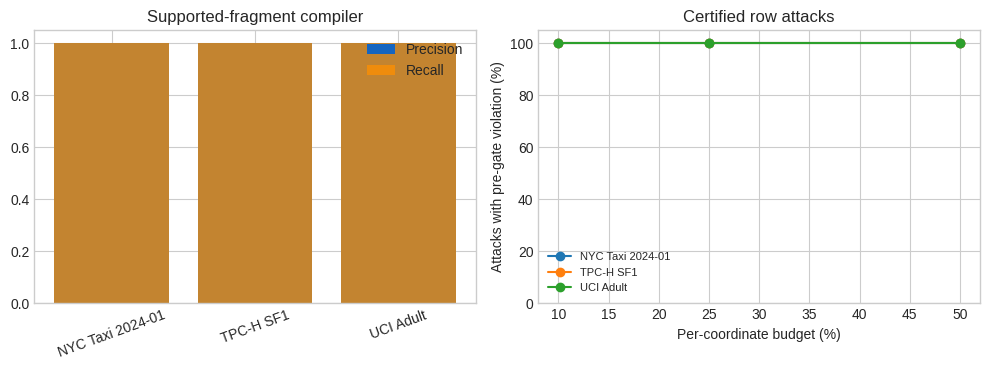

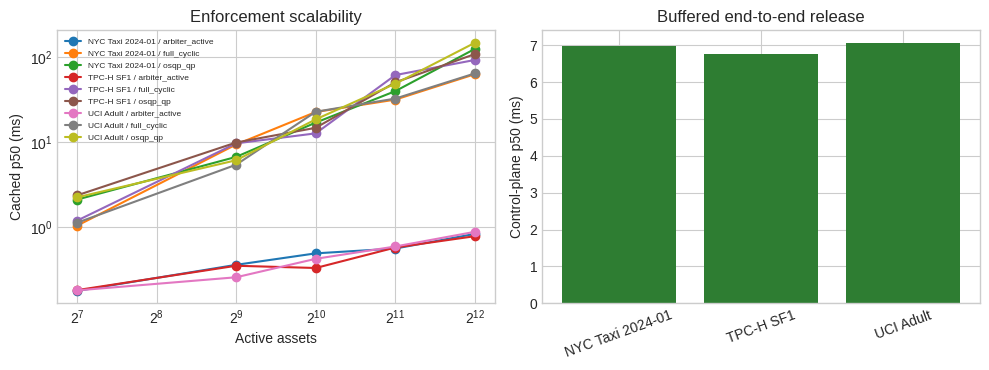

In [7]:
plt.style.use("seaborn-v0_8-whitegrid")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].bar(
    compiler["dataset"],
    compiler["precision"],
    label="Precision",
    color="#1565C0",
)
axes[0].bar(
    compiler["dataset"],
    compiler["recall"],
    label="Recall",
    color="#FF8F00",
    alpha=0.75,
)
axes[0].set_ylim(0, 1.05)
axes[0].set_title("Supported-fragment compiler")
axes[0].tick_params(axis="x", rotation=20)
axes[0].legend()

for dataset, group in attack_summary.groupby("dataset"):
    axes[1].plot(
        100 * group["budget_fraction"],
        100 * group["attack_success_rate"],
        marker="o",
        label=dataset,
    )
axes[1].set_xlabel("Per-coordinate budget (%)")
axes[1].set_ylabel("Attacks with pre-gate violation (%)")
axes[1].set_ylim(0, 105)
axes[1].set_title("Certified row attacks")
axes[1].legend(fontsize=8)
fig.tight_layout()
fig.savefig(
    figures_dir / "fig_compiler_attack.pdf",
    bbox_inches="tight",
)
fig.savefig(
    figures_dir / "fig_compiler_attack.png",
    dpi=220,
    bbox_inches="tight",
)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for (dataset, method), group in scale_summary.groupby(
    ["dataset", "method"]
):
    if method not in ["arbiter_active", "full_cyclic", "osqp_qp"]:
        continue
    axes[0].plot(
        group["scale"],
        group["runtime_p50_ms"],
        marker="o",
        label=f"{dataset} / {method}",
    )
axes[0].set_xscale("log", base=2)
axes[0].set_yscale("log")
axes[0].set_xlabel("Active assets")
axes[0].set_ylabel("Cached p50 (ms)")
axes[0].set_title("Enforcement scalability")
axes[0].legend(fontsize=6)

e2e = (
    end_to_end.groupby(
        ["dataset", "query_profile", "scenario"],
        as_index=False,
    )
    .agg(control_p50_ms=("gate_and_commit_ms", "median"))
)
normal = e2e[
    (e2e["scenario"] == "normal")
    & (e2e["query_profile"] == "aggregate_scalar")
]
axes[1].bar(
    normal["dataset"],
    normal["control_p50_ms"],
    color="#2E7D32",
)
axes[1].set_ylabel("Control-plane p50 (ms)")
axes[1].set_title("Buffered end-to-end release")
axes[1].tick_params(axis="x", rotation=20)
fig.tight_layout()
fig.savefig(
    figures_dir / "fig_scale_protocol.pdf",
    bbox_inches="tight",
)
fig.savefig(
    figures_dir / "fig_scale_protocol.png",
    dpi=220,
    bbox_inches="tight",
)
plt.show()


In [8]:
save_json(
    output_dir / "environment.json",
    environment_manifest(config),
)
stage_checks = []
for stage in [
    workload_dir,
    proposal_dir,
    protocol_dir,
    scale_dir,
    output_dir,
]:
    checks = pd.read_csv(stage / "stage_quality_checks.csv")
    checks.insert(0, "stage", stage.name)
    stage_checks.append(checks)
stage_quality = pd.concat(stage_checks, ignore_index=True)
stage_quality.to_csv(
    output_dir / "all_stage_quality_checks.csv", index=False
)

package_root = RUN_DIR / (
    f"arbiter_icde_evidence_{RUN_MODE}_audited_v4"
)
if package_root.exists():
    shutil.rmtree(package_root)
package_root.mkdir(parents=True)
for stage in [
    workload_dir,
    proposal_dir,
    protocol_dir,
    scale_dir,
    output_dir,
]:
    shutil.copytree(
        stage,
        package_root / stage.name,
        dirs_exist_ok=True,
    )
package_code = package_root / "code"
package_code.mkdir()
for name in [
    "arbiter_core.py",
    "arbiter_data.py",
    "arbiter_experiments.py",
    "arbiter_workload.py",
    "code_manifest.json",
]:
    shutil.copy2(CODE_DIR / name, package_code / name)
shutil.copy2(
    RUN_DIR / "run_config.json",
    package_root / "run_config.json",
)
readme = (
    f"# Arbiter ICDE evidence package ({RUN_MODE}, audited v4)\n\n"
    "This package evaluates a release-time verifier over a declared, "
    "supported SQL fragment and controlled experimental seller-price "
    "labels. It does not claim universal SQL derivability, observed "
    "market prices, distributed atomicity, or equivalence to "
    "published pricing systems.\n\n"
    "Interpret `04_evidence/claim_audit.csv` before drafting "
    "manuscript claims. `NOT_SUPPORTED` and `LIMITED` outcomes must "
    "remain visible. Raw trials are the numerical authority.\n"
)
(package_root / "README.md").write_text(
    "\n".join(
        line.strip()
        for line in readme.strip().splitlines()
    )
    + "\n",
    encoding="utf-8",
)

checksums = checksum_manifest(str(package_root))
checksums.to_csv(
    package_root / "checksums.csv", index=False
)
(package_root / "checksums.sha256").write_text(
    "".join(
        f"{row.sha256}  {row.path}\n"
        for row in checksums.itertuples(index=False)
    ),
    encoding="utf-8",
)

zip_path = RUN_DIR / (
    f"arbiter_icde_evidence_{RUN_MODE}_audited_v4.zip"
)
if zip_path.exists():
    zip_path.unlink()
with zipfile.ZipFile(
    zip_path, "w", compression=zipfile.ZIP_DEFLATED
) as archive:
    for path in sorted(package_root.rglob("*")):
        if path.is_file():
            archive.write(
                path,
                arcname=path.relative_to(package_root.parent),
            )

# Reopen the finished archive and verify every manifest entry from
# the compressed bytes. This catches incomplete/corrupt packaging.
with zipfile.ZipFile(zip_path) as archive:
    bad_member = archive.testzip()
    if bad_member is not None:
        raise RuntimeError(f"Corrupt ZIP member: {bad_member}")
    prefix = package_root.name + "/"
    for row in checksums.itertuples(index=False):
        archived = archive.read(prefix + row.path)
        observed = hashlib.sha256(archived).hexdigest()
        if observed != row.sha256:
            raise RuntimeError(
                f"Archived checksum mismatch: {row.path}"
            )

display(stage_quality)
print("Evidence package:", zip_path)
print("Size:", zip_path.stat().st_size, "bytes")
if not stage_quality["passed"].all():
    print(
        "WARNING: At least one non-fatal stage check did not pass. "
        "Read claim_audit.csv before manuscript revision."
    )
else:
    print("All stage checks pass. The claim ledger still controls scope.")


,stage,check,passed,severity
0,00_workload,exact parser/solver dependency versions,True,NaN
1,00_workload,pinned OSQP backend is available,True,NaN
2,00_workload,supported/unsupported classification,True,NaN
3,00_workload,compiler precision against construction oracle,True,NaN
4,00_workload,compiler recall against construction oracle,True,NaN
5,00_workload,all relation families exist per dataset,True,NaN
6,00_workload,executed bag-semantics relation sample,True,NaN
7,00_workload,semantic sample covers every relation family,True,NaN
8,00_workload,all assets compile in DuckDB EXPLAIN,True,NaN
9,01_proposals_attacks,controlled policies verify,True,fatal


Evidence package: /content/drive/MyDrive/Arbiter_ICDE_2027/runs/full_audited_v4/arbiter_icde_evidence_full_audited_v4.zip
Size: 7263526 bytes
All stage checks pass. The claim ledger still controls scope.
